# Chapter 1: Setting Up and Meeting Your Data

Companion notebook for *Master Exploratory Data Analysis: A Hands-On Beginner's Guide with Python, Statistics & A/B Testing*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files are in the same folder as this notebook.

## 1.2 Getting the Companion Files

### Checking the installation

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import statsmodels

plt.style.use('book.mplstyle')

print('Python', sys.version.split()[0])
for lib in [np, pd, scipy, statsmodels, sns, matplotlib]:
    print(lib.__name__, lib.__version__)

Python 3.14.7
numpy 2.5.3
pandas 3.0.6
scipy 1.18.1
statsmodels 0.15.0
seaborn 0.13.2
matplotlib 3.11.2


## 1.3 Meeting Northpine Coffee Club

### `pd.read_csv()`

In [2]:
customers = pd.read_csv('customers.csv', parse_dates=['signup_date'])
orders = pd.read_csv('orders.csv', parse_dates=['order_date'])
plans = pd.read_csv('plans.csv')
cancellations = pd.read_csv('cancellations.csv',
                            parse_dates=['cancel_date'])

In [3]:
no_dates = pd.read_csv('customers.csv')
no_dates['signup_date'].head(3)

0    2024-01-01
1    2024-01-01
2    2024-01-01
Name: signup_date, dtype: str

### `shape`

In [4]:
print(customers.shape)
print(orders.shape)

(4210, 9)
(28772, 8)


### `df.info()`

In [5]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 4210 entries, 0 to 4209
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   customer_id  4210 non-null   int64         
 1   signup_date  4210 non-null   datetime64[us]
 2   city         4210 non-null   str           
 3   state        4210 non-null   str           
 4   region       4210 non-null   str           
 5   age          4043 non-null   float64       
 6   channel      4210 non-null   str           
 7   plan         4210 non-null   str           
 8   device       4210 non-null   str           
dtypes: datetime64[us](1), float64(1), int64(1), str(6)
memory usage: 440.7 KB


### `df.head()` and `df.sample()`

In [6]:
customers.head(3).T

,0,1,2
customer_id,1001,1002,1003
signup_date,2024-01-01 00:00:00,2024-01-01 00:00:00,2024-01-01 00:00:00
city,Houston,Nashville,Los Angeles
state,TX,TN,CA
region,South,South,West
age,45.0,30.0,40.0
channel,Podcast,Email,Email
plan,Basic,Basic,Standard
device,Desktop,Desktop,Mobile


In [7]:
customers.sample(3, random_state=42)[
    ['customer_id', 'signup_date', 'city', 'plan', 'device']]

,customer_id,signup_date,city,plan,device
1073,2074,2024-09-11,Seattle,Basic,Desktop
144,1145,2024-02-05,Phoenix,Standard,Mobile
2380,3381,2025-04-18,Chicago,Standard,Mobile


In [8]:
orders.head(3).T

,0,1,2
order_id,100001,100002,100003
customer_id,1001,1002,1003
order_date,2024-01-01 00:00:00,2024-01-01 00:00:00,2024-01-01 00:00:00
order_type,Subscription,Subscription,Subscription
items,1,1,1
amount,8.0,8.0,14.0
discount,8.0,8.0,14.0
delivery_days,2,2,4


In [9]:
plans

,plan,monthly_price,bags_per_month
0,Basic,16.0,1
1,Standard,28.0,2
2,Premium,49.0,4


### `df.dtypes`

In [10]:
orders.dtypes

order_id                  int64
customer_id               int64
order_date       datetime64[us]
order_type                  str
items                     int64
amount                  float64
discount                float64
delivery_days             int64
dtype: object

### `df.nunique()`

In [11]:
customers.nunique()

customer_id    4210
signup_date     725
city             20
state            17
region            4
age              56
channel           5
plan              3
device            2
dtype: int64

### `df.memory_usage()`

In [12]:
(customers.memory_usage(deep=True) / 1024).round(1)

Index           0.1
customer_id    32.9
signup_date    32.9
city           65.6
state          41.1
region         57.7
age            32.9
channel        58.9
plan           59.5
device         59.1
dtype: float64

In [13]:
print(f'{orders.memory_usage(deep=True).sum() / 1024**2:.1f} MB')

2.1 MB


## 1.4 A pandas and seaborn Recap

### Selecting, filtering and sorting

In [14]:
orders[['order_id', 'order_type', 'amount']].head(3)

,order_id,order_type,amount
0,100001,Subscription,8.0
1,100002,Subscription,8.0
2,100003,Subscription,14.0


In [15]:
big_add_ons = orders[(orders['order_type'] == 'Add-on')
                     & (orders['amount'] > 100)]
big_add_ons.shape

(29, 8)

In [16]:
top_orders = orders.sort_values('amount', ascending=False)
top_orders[['order_id', 'order_type', 'items', 'amount']].head(3)

,order_id,order_type,items,amount
9144,109145,Add-on,25,635.74
23411,123412,Add-on,15,630.63
18022,118023,Add-on,11,619.16


### Adding a column

In [17]:
orders['amount_per_bag'] = (orders['amount'] / orders['items']).round(2)
orders[['order_type', 'items', 'amount', 'amount_per_bag']].head(3)

,order_type,items,amount,amount_per_bag
0,Subscription,1,8.0,8.0
1,Subscription,1,8.0,8.0
2,Subscription,1,14.0,14.0


### `s.value_counts()`

In [18]:
customers['plan'].value_counts()

plan
Basic       1887
Standard    1511
Premium      812
Name: count, dtype: int64

### `groupby()`

In [19]:
orders.groupby('order_type')['amount'].mean().round(2)

order_type
Add-on          25.82
Subscription    27.15
Name: amount, dtype: float64

### A single number, and `np.float64`

In [20]:
orders['amount'].mean()

np.float64(26.93789309050466)

### f-strings

In [21]:
total = orders['amount'].sum()
late = (orders['delivery_days'] > 5).mean()
print(f'Total revenue: ${total:,.2f}')
print(f'Late boxes: {late:.1%}')

Total revenue: $775,057.06
Late boxes: 9.0%


### A short function

In [22]:
def share_late(days):
    return (days > 5).mean()

add_on_days = orders[orders['order_type'] == 'Add-on']['delivery_days']
print(f'All orders: {share_late(orders["delivery_days"]):.1%}')
print(f'Add-ons only: {share_late(add_on_days):.1%}')

All orders: 9.0%
Add-ons only: 10.3%


### Quick charts

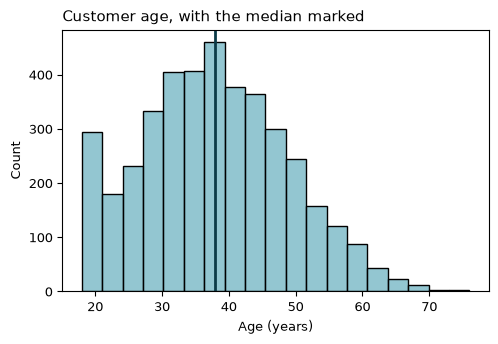

In [23]:
median_age = customers['age'].median()

fig, ax = plt.subplots()
sns.histplot(data=customers, x='age', binwidth=3, color='#6fb3c2',
             ax=ax)
ax.axvline(median_age, color='#0b3a47')
ax.set_title('Customer age, with the median marked')
ax.set_xlabel('Age (years)')
plt.show()

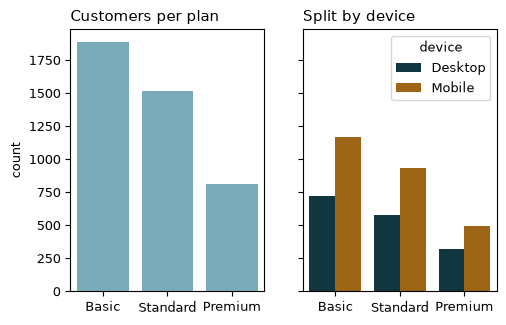

In [24]:
plan_order = ['Basic', 'Standard', 'Premium']

fig, axes = plt.subplots(1, 2, sharey=True)
sns.countplot(data=customers, x='plan', order=plan_order,
              color='#6fb3c2', ax=axes[0])
sns.countplot(data=customers, x='plan', order=plan_order,
              hue='device', palette=['#0b3a47', '#b26a00'],
              ax=axes[1])
axes[0].set_title('Customers per plan')
axes[1].set_title('Split by device')
for ax in axes:
    ax.set_xlabel('')
plt.show()

## 1.5 Joining Tables

### `df.merge()`

In [25]:
orders_customers = orders.merge(customers, on='customer_id',
                                validate='many_to_one')
print(f'Orders before: {len(orders):,}')
print(f'Merged after:  {len(orders_customers):,}')
print(f'Columns: {orders.shape[1]} + {customers.shape[1]} '
      f'- 1 shared key = {orders_customers.shape[1]}')

Orders before: 28,772
Merged after:  28,772
Columns: 9 + 9 - 1 shared key = 17


In [26]:
revenue_by_plan = orders_customers.groupby('plan')['amount'].sum()
revenue_by_plan.round(0)

plan
Basic       146653.0
Premium     325684.0
Standard    302720.0
Name: amount, dtype: float64

### What a left join does

In [27]:
small_customers = pd.DataFrame({'customer_id': [1, 2, 4],
                                'name': ['Ava', 'Ben', 'Dev']})
small_orders = pd.DataFrame({'order_id': [10, 11, 12, 13],
                             'customer_id': [1, 1, 2, 3],
                             'amount': [8.0, 14.0, 8.0, 20.0]})

inner = small_orders.merge(small_customers, on='customer_id')
inner

,order_id,customer_id,amount,name
0,10,1,8.0,Ava
1,11,1,14.0,Ava
2,12,2,8.0,Ben


In [28]:
left = small_orders.merge(small_customers, on='customer_id',
                          how='left')
left

,order_id,customer_id,amount,name
0,10,1,8.0,Ava
1,11,1,14.0,Ava
2,12,2,8.0,Ben
3,13,3,20.0,NaN


In [29]:
customers_status = customers.merge(cancellations, on='customer_id',
                                   how='left', validate='one_to_one')
print(f'Customers: {len(customers):,}')
print(f'After the left join: {len(customers_status):,}')
no_row = customers_status['cancel_date'].isna().sum()
print(f'No cancellation row: {no_row:,}')

Customers: 4,210
After the left join: 4,210
No cancellation row: 1,841


In [30]:
cancelled_orders = orders.merge(cancellations, on='customer_id')
print(f'{len(orders):,} orders became {len(cancelled_orders):,}')

28,772 orders became 12,422


### When the key goes wrong

In [31]:
dup_customers = pd.DataFrame(
    {'customer_id': [1, 2, 2, 3],
     'name': ['Ava', 'Ben', 'Benjamin', 'Cara']})
repeated = small_orders.merge(dup_customers, on='customer_id')
print(f'{len(small_orders)} orders became {len(repeated)} rows')
repeated

4 orders became 5 rows


,order_id,customer_id,amount,name
0,10,1,8.0,Ava
1,11,1,14.0,Ava
2,12,2,8.0,Ben
3,12,2,8.0,Benjamin
4,13,3,20.0,Cara


The next cell raises an error on purpose.

In [32]:
small_orders.merge(dup_customers, on='customer_id',
                   validate='many_to_one')

MergeError: Merge keys are not unique in right dataset; not a many-to-one merge

Duplicates in right:
  customer_id
           2 ...

Shown in the book but not run here:

```python
text_ids = customers.astype({'customer_id': 'str'})
orders.merge(text_ids, on='customer_id')
```

## 1.6 When Something Doesn't Work

### A library that isn't installed

Shown in the book but not run here:

```python
import seaborn as sns
```

### A data file that can't be found

The next cell raises an error on purpose.

In [33]:
pd.read_csv('order.csv')

FileNotFoundError: [Errno 2] No such file or directory: 'order.csv'

### A style file that can't be found

Shown in the book but not run here:

```python
plt.style.use('book_style.mplstyle')
```